In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame

print(df.head())
print("Dataset shape:", df.shape)

In [1]:
# Step 1: Import libraries and load the Iris dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame.copy()

# Add readable species names
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

Dataset loaded successfully!
Dataset shape: (150, 6)

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  


In [2]:
# Check data types
print("Dataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
print("\nStatistical summary:")
print(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Duplicate rows: 1

Statistical summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066 

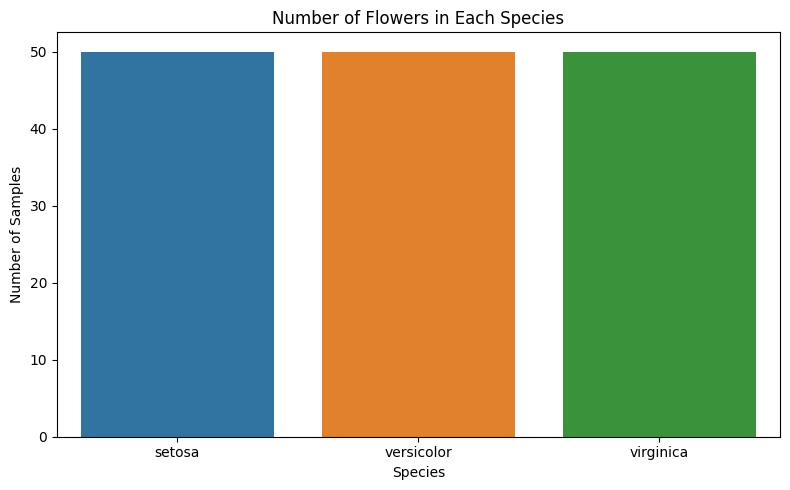

In [3]:
# Count flowers in each species

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species",
    hue="species",
    legend=False
)

plt.title("Number of Flowers in Each Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

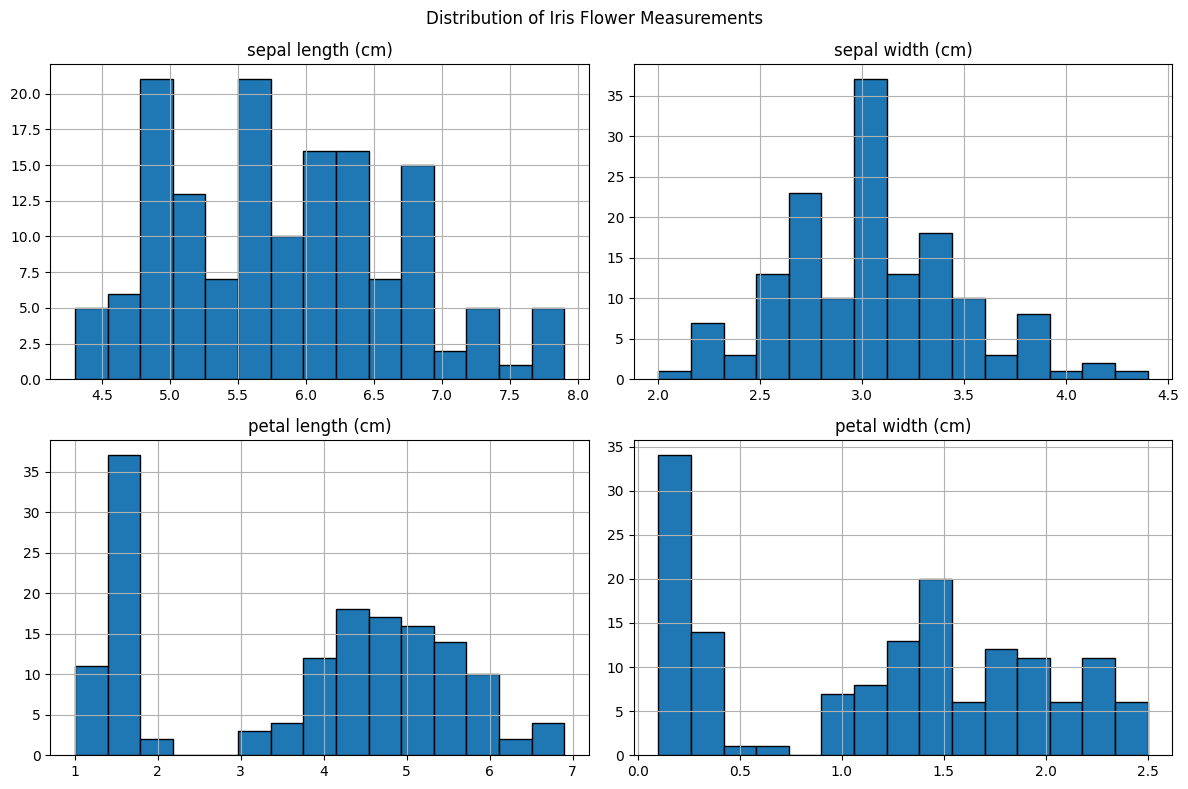

In [4]:
# Visualize the distribution of four features

df[iris.feature_names].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Flower Measurements")
plt.tight_layout()
plt.show()

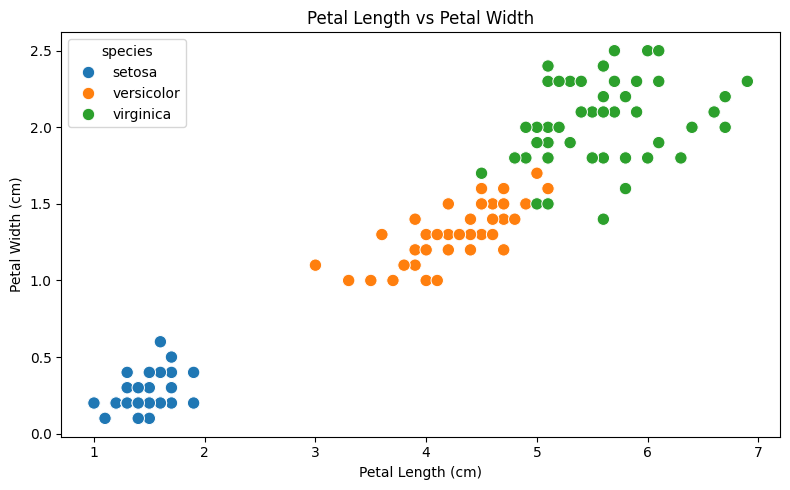

In [5]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=80
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.tight_layout()
plt.show()

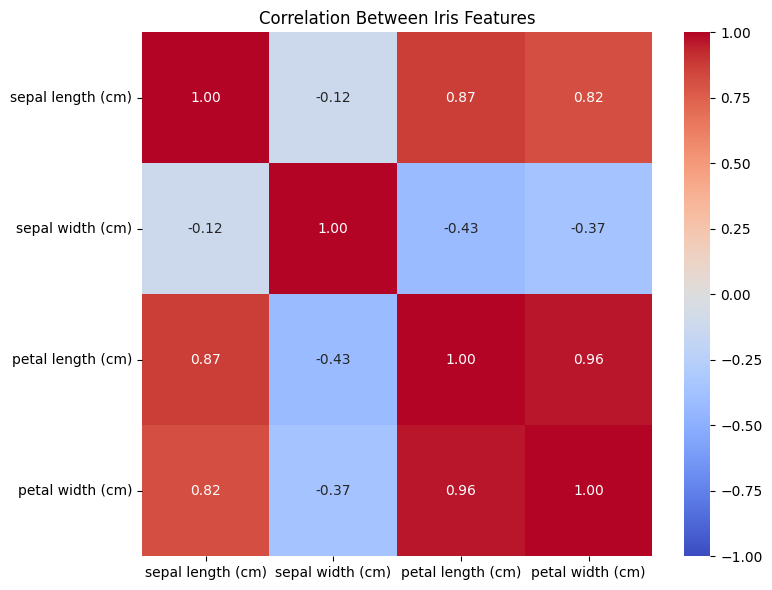

In [6]:
plt.figure(figsize=(8, 6))

correlation = df[iris.feature_names].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Iris Features")
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

# Input features and target labels
X = iris.data
y = iris.target

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training samples: 120
Testing samples: 30
Training data shape: (120, 4)
Testing data shape: (30, 4)


In [8]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [9]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Predict the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro"
)
recall = recall_score(
    y_test, y_pred, average="macro"
)
f1 = f1_score(
    y_test, y_pred, average="macro"
)

print(f"Accuracy:  {accuracy:.4f} ({accuracy:.2%})")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Accuracy:  0.9000 (90.00%)
Precision: 0.9024
Recall:    0.9000
F1-score:  0.8997

Detailed Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



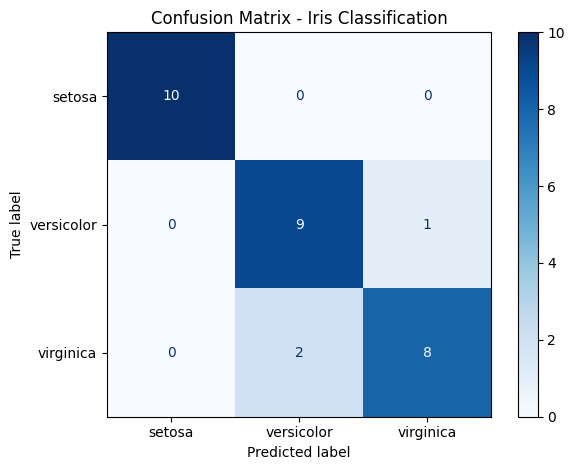

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Iris Classification")
plt.tight_layout()
plt.show()

In [11]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = model.predict(new_flower)[0]
probabilities = model.predict_proba(new_flower)[0]

print("New Flower Measurements:")
print(new_flower)

print("\nPredicted Species:", iris.target_names[prediction])

print("\nPrediction Probabilities:")
for species, probability in zip(
    iris.target_names, probabilities
):
    print(f"{species}: {probability:.2%}")

New Flower Measurements:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2

Predicted Species: setosa

Prediction Probabilities:
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%


Feature Importance:
petal width (cm)     0.437185
petal length (cm)    0.431466
sepal length (cm)    0.116349
sepal width (cm)     0.015000
dtype: float64


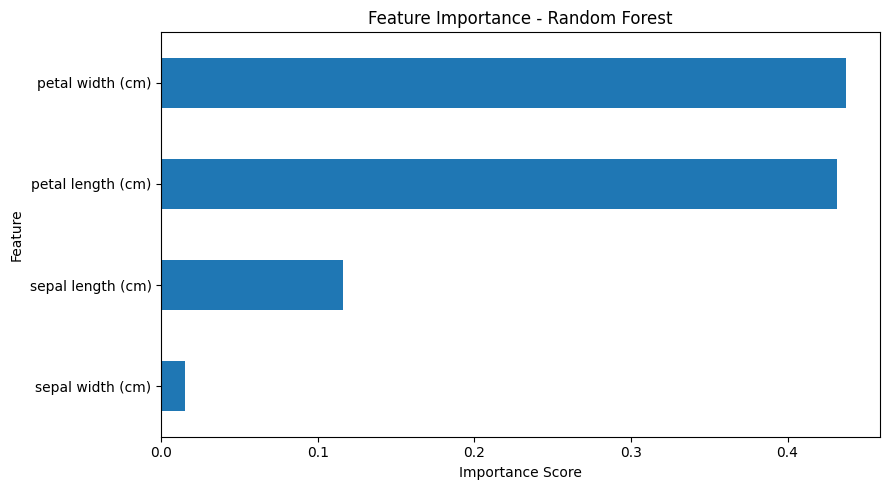

In [12]:
importance = pd.Series(
    model.feature_importances_,
    index=iris.feature_names
).sort_values(ascending=False)

print("Feature Importance:")
print(importance)

plt.figure(figsize=(9, 5))

importance.sort_values().plot(kind="barh")

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [13]:
import joblib

joblib.dump(model, "iris_random_forest_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [14]:
print("=" * 45)
print("IRIS FLOWER CLASSIFICATION - FINAL SUMMARY")
print("=" * 45)

print("Dataset samples:", len(df))
print("Number of features:", X.shape[1])
print("Number of species:", len(iris.target_names))
print("Model: Random Forest Classifier")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"Test Accuracy: {accuracy:.2%}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1-score: {f1:.4f}")

print("\nSpecies:", list(iris.target_names))
print("\nProject completed!")

IRIS FLOWER CLASSIFICATION - FINAL SUMMARY
Dataset samples: 150
Number of features: 4
Number of species: 3
Model: Random Forest Classifier
Training samples: 120
Testing samples: 30
Test Accuracy: 90.00%
Macro Precision: 0.9024
Macro Recall: 0.9000
Macro F1-score: 0.8997

Species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Project completed!
